# 07 · Experiment E2: which loss? (task T23, runs R10 to R15)

**RQ2.** Water is under 10% of the labelled pixels. Which loss copes best with that imbalance? Everything else is the frozen default (MobileNetV2 encoder, VV + VH + ratio input):

| Config | Loss | Runs |
|---|---|---|
| BCE loss | binary cross-entropy, averaged over valid pixels | R10, R11, R12 |
| Dice loss | 1 − Dice overlap with the water class | R13, R14, R15 |
| Default | BCE + Dice | R01, R02, R03 (shared with E1) |

BCE judges every pixel on its own, so the many easy "not water" pixels dominate it; Dice scores the overlap with the water class directly. Precision and recall are reported next to IoU because the losses are expected to trade one for the other.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis, viz
from src.config import STUDIES, load_config, run_table, runs_of
from src.runner import check_frozen, run_benchmark, run_evaluation, run_many

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("training and scoring code is identical to the frozen tag 'defaults-frozen' (commit %s)" % check_frozen()[:7])

STUDY = "E2"
CONFIGS = STUDIES[STUDY]["configs"]
pd.DataFrame([r for r in run_table() if r["config_name"] in CONFIGS]).fillna({"loss": "bce_dice"}).set_index("run_id")

training and scoring code is identical to the frozen tag 'defaults-frozen' (commit 43821af)


,config_name,study,seed,loss
run_id,,,,
R01,Default,"E1, E2, E3 (shared)",0,bce_dice
R02,Default,"E1, E2, E3 (shared)",1,bce_dice
R03,Default,"E1, E2, E3 (shared)",2,bce_dice
R10,BCE loss,E2,0,bce
R11,BCE loss,E2,1,bce
R12,BCE loss,E2,2,bce
R13,Dice loss,E2,0,dice
R14,Dice loss,E2,1,dice
R15,Dice loss,E2,2,dice


## 1. Train and score R10 to R15

In [2]:
results = run_many(["R10", "R11", "R12", "R13", "R14", "R15"])


[R10 was trained on 2026-11-11 14:23 UTC; this is its saved log]
R10: BCE loss | encoder mobilenetv2 | channels vv_vh_ratio | loss bce | seed 0 | 5,419,473 parameters | mixed_float16
epoch  1/60 | loss 0.3686  iou 0.3568 | val_loss 1.0770  val_iou 0.1102 | lr 1.0e-03 | 171.3s *
epoch  2/60 | loss 0.2382  iou 0.3574 | val_loss 0.2175  val_iou 0.4108 | lr 1.0e-03 |   7.8s *
epoch  3/60 | loss 0.2006  iou 0.4063 | val_loss 0.2560  val_iou 0.3343 | lr 1.0e-03 |   7.9s
epoch  4/60 | loss 0.1783  iou 0.4531 | val_loss 0.2207  val_iou 0.4069 | lr 1.0e-03 |   7.6s
epoch  5/60 | loss 0.1772  iou 0.4153 | val_loss 0.1897  val_iou 0.3784 | lr 1.0e-03 |   7.7s
epoch  6/60 | loss 0.1687  iou 0.4253 | val_loss 0.1465  val_iou 0.5693 | lr 1.0e-03 |   7.6s *
epoch  7/60 | loss 0.1555  iou 0.4592 | val_loss 0.1616  val_iou 0.5431 | lr 1.0e-03 |   7.8s
epoch  8/60 | loss 0.1523  iou 0.5220 | val_loss 0.1910  val_iou 0.5895 | lr 1.0e-03 |   7.7s *
epoch  9/60 | loss 0.1481  iou 0.5218 | val_loss 0.2389 

## 2. Results

One row per run. Validation IoU is the score the checkpoint was chosen by; test and Bolivia were scored once, after training.

In [3]:
runs = analysis.runs_table()
study_runs = runs[runs["Config"].isin(CONFIGS)]
study_runs[["Run ID", "Config", "Seed", "Status", "Epochs trained", "Best epoch", "Val IoU (best)", "Test IoU",
            "Test precision", "Test recall", "Bolivia IoU", "Sec per epoch"]].set_index("Run ID")

,Config,Seed,Status,Epochs trained,Best epoch,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU,Sec per epoch
Run ID,,,,,,,,,,,
R01,Default,0,Finished,39.0000,24.0000,0.6282,0.6681,0.8520,0.7558,0.6547,8.6400
R02,Default,1,Finished,32.0000,17.0000,0.6449,0.6640,0.8437,0.7571,0.6213,8.4400
R03,Default,2,Finished,34.0000,19.0000,0.6435,0.6674,0.8135,0.7880,0.6347,8.5900
R10,BCE loss,0,Finished,47.0000,32.0000,0.6198,0.6546,0.8788,0.7196,0.5876,8.0300
R11,BCE loss,1,Finished,44.0000,29.0000,0.6056,0.6421,0.8686,0.7112,0.4279,8.0500
R12,BCE loss,2,Finished,39.0000,24.0000,0.6224,0.6331,0.8109,0.7427,0.6624,8.0200
R13,Dice loss,0,Finished,30.0000,15.0000,0.6488,0.6570,0.8310,0.7583,0.6253,8.2100
R14,Dice loss,1,Finished,35.0000,20.0000,0.6364,0.6526,0.8160,0.7652,0.6039,8.2100
R15,Dice loss,2,Finished,39.0000,24.0000,0.6463,0.6716,0.8367,0.7730,0.6419,8.2600


Mean ± standard deviation over the three seeds (the two threshold baselines, single deterministic runs, are shown for reference):

In [4]:
analysis.study_table(STUDY, analysis.summary_table(runs))

,Finished runs,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU
Config,,,,,,
Otsu (E0),1,0.388,0.433,0.483,0.809,0.653
Tuned VH threshold,1,0.492,0.524,0.747,0.637,0.531
BCE loss,3,0.616 ± 0.009,0.643 ± 0.011,0.853 ± 0.037,0.725 ± 0.016,0.559 ± 0.120
Dice loss,3,0.644 ± 0.007,0.660 ± 0.010,0.828 ± 0.011,0.765 ± 0.007,0.624 ± 0.019
Default,3,0.639 ± 0.009,0.667 ± 0.002,0.836 ± 0.020,0.767 ± 0.018,0.637 ± 0.017


**Is a difference real?** The project's rule: a gap between two configs counts only if it is larger than the seed-to-seed standard deviation.

In [5]:
gaps = analysis.gap_table(STUDY, runs)
gaps.to_csv(ROOT / "results" / f"{STUDY}_gaps.csv", index=False)
gaps.set_index(["Metric", "A", "B"])

,,,Mean A,Mean B,Gap (A - B),Larger std,Gap / std,Gap larger than std,Welch p
Metric,A,B,,,,,,,
Test IoU,BCE loss,Dice loss,0.6433,0.6604,-0.0171,0.0108,1.5810,True,0.1149
Bolivia IoU,BCE loss,Dice loss,0.5593,0.6237,-0.0644,0.1198,0.5375,False,0.4509
Test IoU,BCE loss,Default,0.6433,0.6665,-0.0232,0.0108,2.1461,True,0.0601
Bolivia IoU,BCE loss,Default,0.5593,0.6369,-0.0776,0.1198,0.6475,False,0.3786
Test IoU,Dice loss,Default,0.6604,0.6665,-0.0061,0.0100,0.6128,False,0.4005
Bolivia IoU,Dice loss,Default,0.6237,0.6369,-0.0132,0.0190,0.6925,False,0.4205


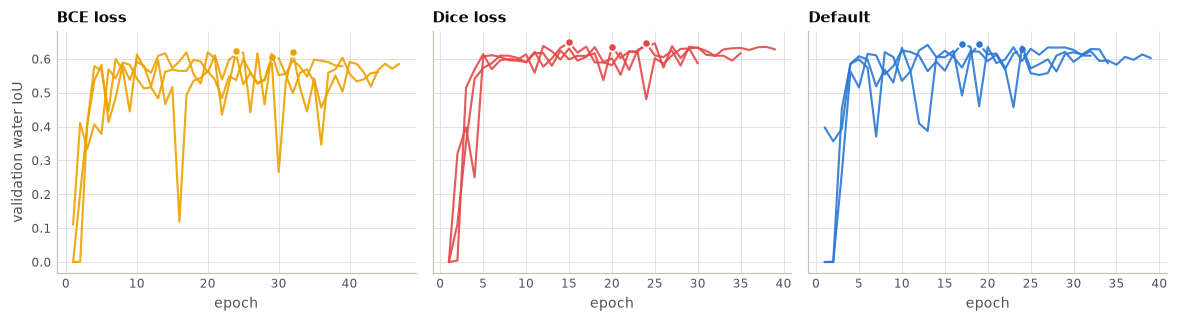

In [6]:
hist = {c: analysis.histories(runs_of(c)) for c in CONFIGS}
axes = viz.plot_val_curves(hist)
axes[0].figure.tight_layout()
viz.savefig(axes[0].figure, ROOT / "figures" / f"{STUDY}_val_curves.png")
plt.show()

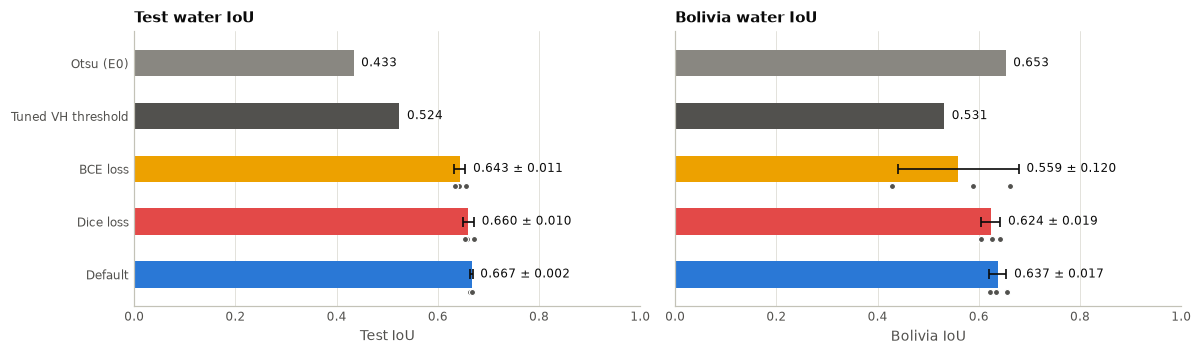

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
done = runs[runs["Status"] == "Finished"]
for ax, metric in zip(axes, ("Test IoU", "Bolivia IoU")):
    viz.plot_config_bars(done, CONFIGS, metric, ax, baseline=("Otsu (E0)", "Tuned VH threshold"))
    ax.set_title(metric.replace("IoU", "water IoU"))
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / f"{STUDY}_bars.png")
plt.show()

Precision and recall on the test split, per run:

In [8]:
pr = study_runs[["Run ID", "Config", "Seed", "Test precision", "Test recall", "Test F1", "Bolivia precision", "Bolivia recall"]]
pr.set_index("Run ID")

,Config,Seed,Test precision,Test recall,Test F1,Bolivia precision,Bolivia recall
Run ID,,,,,,,
R01,Default,0,0.8520,0.7558,0.8010,0.8890,0.7130
R02,Default,1,0.8437,0.7571,0.7981,0.8905,0.6727
R03,Default,2,0.8135,0.7880,0.8005,0.8544,0.7116
R10,BCE loss,0,0.8788,0.7196,0.7913,0.8911,0.6331
R11,BCE loss,1,0.8686,0.7112,0.7821,0.8984,0.4497
R12,BCE loss,2,0.8109,0.7427,0.7753,0.8828,0.7263
R13,Dice loss,0,0.8310,0.7583,0.7930,0.8694,0.6901
R14,Dice loss,1,0.8160,0.7652,0.7898,0.8714,0.6630
R15,Dice loss,2,0.8367,0.7730,0.8036,0.8492,0.7244


## 3. Reading (RQ2)

* **BCE alone is the weakest loss on the test chips.** 0.643 ± 0.011, against 0.660 ± 0.010 for Dice and 0.667 ± 0.002 for BCE+Dice. The gaps to BCE (0.017 and 0.023) are larger than the spread between seeds, so by the project's rule they are real; with three seeds a t-test stays inconclusive (p = 0.11 and 0.06), so "probably real" is the honest wording.
* **The mechanism is the expected one.** BCE has the highest precision (0.853) and the lowest recall (0.725): judged pixel by pixel, the cheapest way to be right is to under-predict the rare class. The two Dice-based losses find more water (recall 0.765 and 0.767) for slightly lower precision (0.828 and 0.836).
* **Dice alone and BCE+Dice cannot be told apart** (gap 0.006, smaller than the spread). Adding BCE to Dice does not change the score; it does make the three seeds agree more closely (std 0.002 against 0.010).
* **On Bolivia BCE is unstable.** The three seeds give 0.588, 0.428 and 0.662; in the middle one recall collapses to 0.45. The Dice-based losses stay within 0.60 to 0.65. With a spread of 0.12, no Bolivia gap involving BCE counts as real, but the instability itself is a reason not to use BCE alone.
* Dice-trained runs stopped earliest (30 to 39 epochs).